LAB 07
Image Representation, PCA, Eigenfaces and Face Recognition

Part A - Image Representation

In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

np.random.seed(42)

In [30]:
DATA_DIR = Path("att_faces")

images = []
labels = []

for subject in range(1, 41):
    subject_folder = DATA_DIR / f"s{subject}"

    for image_number in range(1, 11):
        image_path = subject_folder / f"{image_number}.pgm"

        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise FileNotFoundError(f"Image not found: {image_path}")

        images.append(image)
        labels.append(subject)

images = np.array(images)
labels = np.array(labels)

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First image dimensions:", images[0].shape)
print("Minimum intensity:", images[0].min())
print("Maximum intensity:", images[0].max())
print("Number of subjects:", len(np.unique(labels)))
print("Images per subject:", Counter(labels))

Images shape: (400, 112, 92)
Labels shape: (400,)
First image dimensions: (112, 92)
Minimum intensity: 11
Maximum intensity: 234
Number of subjects: 40
Images per subject: Counter({np.int64(1): 10, np.int64(2): 10, np.int64(3): 10, np.int64(4): 10, np.int64(5): 10, np.int64(6): 10, np.int64(7): 10, np.int64(8): 10, np.int64(9): 10, np.int64(10): 10, np.int64(11): 10, np.int64(12): 10, np.int64(13): 10, np.int64(14): 10, np.int64(15): 10, np.int64(16): 10, np.int64(17): 10, np.int64(18): 10, np.int64(19): 10, np.int64(20): 10, np.int64(21): 10, np.int64(22): 10, np.int64(23): 10, np.int64(24): 10, np.int64(25): 10, np.int64(26): 10, np.int64(27): 10, np.int64(28): 10, np.int64(29): 10, np.int64(30): 10, np.int64(31): 10, np.int64(32): 10, np.int64(33): 10, np.int64(34): 10, np.int64(35): 10, np.int64(36): 10, np.int64(37): 10, np.int64(38): 10, np.int64(39): 10, np.int64(40): 10})


displaying some images

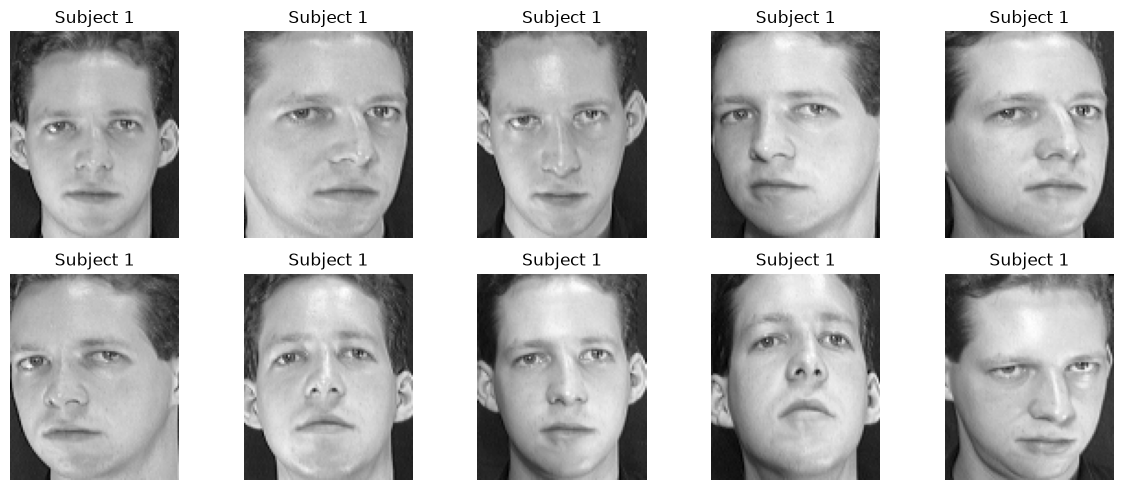

In [31]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(f"Subject {labels[i]}")
    plt.axis("off")

plt.tight_layout()
plt.savefig("sample_faces.png", dpi=150)
plt.show()

flattening the images

In [32]:
X = images.reshape(len(images), -1)
y = labels

print("Complete image matrix:", X.shape)
print("Subject labels:", y.shape)
print("First image feature vector:", X[0][:10])

Complete image matrix: (400, 10304)
Subject labels: (400,)
First image feature vector: [48 49 45 47 49 57 39 42 53 49]


In [33]:
# reproducible stratified train test split
train_indices = []
test_indices = []

rng = np.random.default_rng(42)

for subject in np.unique(y):
    subject_indices = np.where(y == subject)[0]
    subject_indices = rng.permutation(subject_indices)

    train_indices.extend(subject_indices[:8])
    test_indices.extend(subject_indices[8:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training images per subject:", Counter(y_train))
print("Testing images per subject:", Counter(y_test))

Training data: (320, 10304)
Testing data: (80, 10304)
Training images per subject: Counter({np.int64(1): 8, np.int64(2): 8, np.int64(3): 8, np.int64(4): 8, np.int64(5): 8, np.int64(6): 8, np.int64(7): 8, np.int64(8): 8, np.int64(9): 8, np.int64(10): 8, np.int64(11): 8, np.int64(12): 8, np.int64(13): 8, np.int64(14): 8, np.int64(15): 8, np.int64(16): 8, np.int64(17): 8, np.int64(18): 8, np.int64(19): 8, np.int64(20): 8, np.int64(21): 8, np.int64(22): 8, np.int64(23): 8, np.int64(24): 8, np.int64(25): 8, np.int64(26): 8, np.int64(27): 8, np.int64(28): 8, np.int64(29): 8, np.int64(30): 8, np.int64(31): 8, np.int64(32): 8, np.int64(33): 8, np.int64(34): 8, np.int64(35): 8, np.int64(36): 8, np.int64(37): 8, np.int64(38): 8, np.int64(39): 8, np.int64(40): 8})
Testing images per subject: Counter({np.int64(1): 2, np.int64(2): 2, np.int64(3): 2, np.int64(4): 2, np.int64(5): 2, np.int64(6): 2, np.int64(7): 2, np.int64(8): 2, np.int64(9): 2, np.int64(10): 2, np.int64(11): 2, np.int64(12): 2, np.i

PART B - PCA, Eigenfaces and Compression

computing the mean face and centering the training data

Mean face shape: (10304,)
Centered training data: (320, 10304)
Centered test data: (80, 10304)


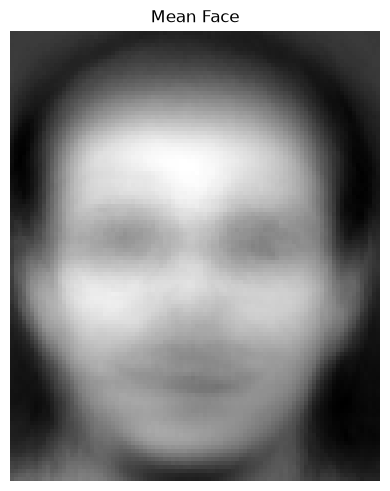

In [34]:
mean_face = np.mean(X_train, axis=0)

X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Mean face shape:", mean_face.shape)
print("Centered training data:", X_train_centered.shape)
print("Centered test data:", X_test_centered.shape)

plt.figure(figsize=(4, 5))
plt.imshow(mean_face.reshape(images.shape[1:]), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.tight_layout()
plt.savefig("mean_face.png", dpi=150)
plt.show()

In [35]:
covariance_matrix = (
    X_train_centered @ X_train_centered.T
) / (len(X_train_centered) - 1)

eigenvalues_cov, eigenvectors_cov = np.linalg.eigh(
    covariance_matrix
)

order = np.argsort(eigenvalues_cov)[::-1]

eigenvalues_cov = eigenvalues_cov[order]
eigenvectors_cov = eigenvectors_cov[:, order]

eigenvalues_cov = np.maximum(eigenvalues_cov, 0)

valid = eigenvalues_cov > 1e-10

eigenvalues_cov = eigenvalues_cov[valid]
eigenvectors_cov = eigenvectors_cov[:, valid]

eigenfaces_cov = (
    X_train_centered.T @ eigenvectors_cov
) / np.sqrt(
    (len(X_train_centered) - 1) * eigenvalues_cov
)

print("Covariance matrix shape:", covariance_matrix.shape)
print("Number of valid eigenvalues:", len(eigenvalues_cov))
print("Eigenfaces shape:", eigenfaces_cov.shape)

Covariance matrix shape: (320, 320)
Number of valid eigenvalues: 320
Eigenfaces shape: (10304, 320)


PCA using SVD

In [36]:
U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

eigenfaces_svd = Vt.T

eigenvalues_svd = (
    singular_values ** 2
) / (len(X_train_centered) - 1)

print("U shape:", U.shape)
print("Singular values shape:", singular_values.shape)
print("V transpose shape:", Vt.shape)
print("SVD eigenfaces shape:", eigenfaces_svd.shape)

U shape: (320, 320)
Singular values shape: (320,)
V transpose shape: (320, 10304)
SVD eigenfaces shape: (10304, 320)


comparing the leading eigenvalues

Maximum eigenvalue difference: 8.731149137020111e-10
Maximum cumulative variance difference: 2.220446049250313e-16

First 10 covariance eigenvalues:
[2837009.98929293 2013339.00426591 1131088.32713936  899267.53112397
  794485.75315848  527768.69018745  397965.00499614  368344.01904347
  319679.26886798  296846.18698546]

First 10 SVD eigenvalues:
[2837009.98929293 2013339.00426591 1131088.32713936  899267.53112397
  794485.75315848  527768.69018745  397965.00499614  368344.01904347
  319679.26886798  296846.18698546]


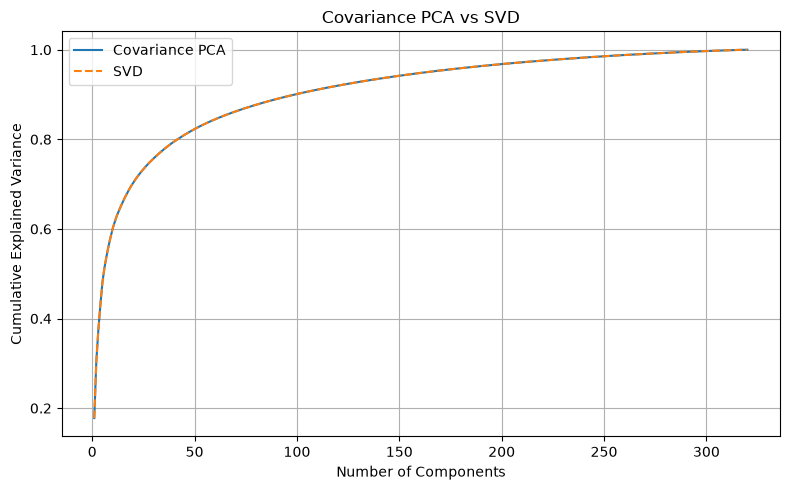

In [37]:
number_to_compare = min(
    len(eigenvalues_cov),
    len(eigenvalues_svd)
)

eigenvalue_difference = np.max(
    np.abs(
        eigenvalues_cov[:number_to_compare]
        - eigenvalues_svd[:number_to_compare]
    )
)

# Calculate explained variance
variance_cov = (
    eigenvalues_cov / np.sum(eigenvalues_cov)
)

variance_svd = (
    eigenvalues_svd / np.sum(eigenvalues_svd)
)

cumulative_cov = np.cumsum(variance_cov)
cumulative_svd = np.cumsum(variance_svd)

variance_difference = np.max(
    np.abs(
        cumulative_cov[:number_to_compare]
        - cumulative_svd[:number_to_compare]
    )
)

print("Maximum eigenvalue difference:", eigenvalue_difference)
print("Maximum cumulative variance difference:", variance_difference)

print("\nFirst 10 covariance eigenvalues:")
print(eigenvalues_cov[:10])

print("\nFirst 10 SVD eigenvalues:")
print(eigenvalues_svd[:10])

plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, len(cumulative_cov) + 1),
    cumulative_cov,
    label="Covariance PCA"
)
plt.plot(
    np.arange(1, len(cumulative_svd) + 1),
    cumulative_svd,
    linestyle="--",
    label="SVD"
)
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Covariance PCA vs SVD")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("pca_method_comparison.png", dpi=150)
plt.show()

Explained variance and minimum components for 90%

Components required for 90% variance: 99
Actual cumulative variance: 0.9001205149458138


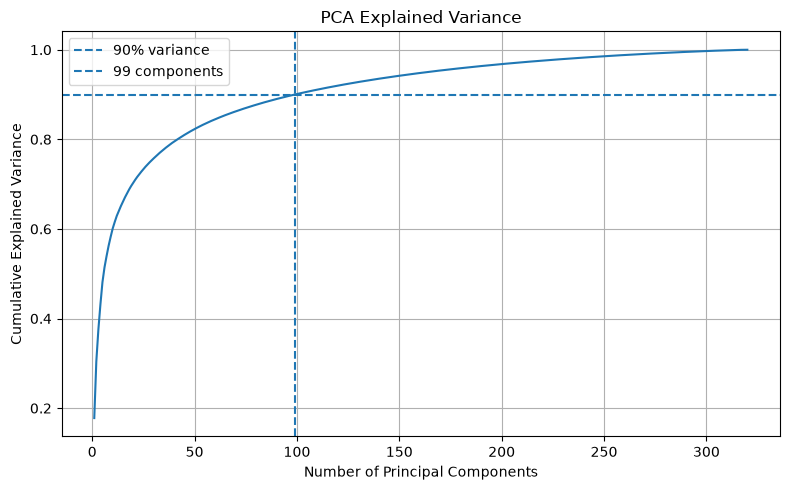

In [38]:
cumulative_variance = np.cumsum(variance_svd)

n_components_90 = (
    np.argmax(cumulative_variance >= 0.90) + 1
)

print("Components required for 90% variance:", n_components_90)
print(
    "Actual cumulative variance:",
    cumulative_variance[n_components_90 - 1]
)

plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance
)
plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance"
)
plt.axvline(
    x=n_components_90,
    linestyle="--",
    label=f"{n_components_90} components"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("explained_variance.png", dpi=150)
plt.show()

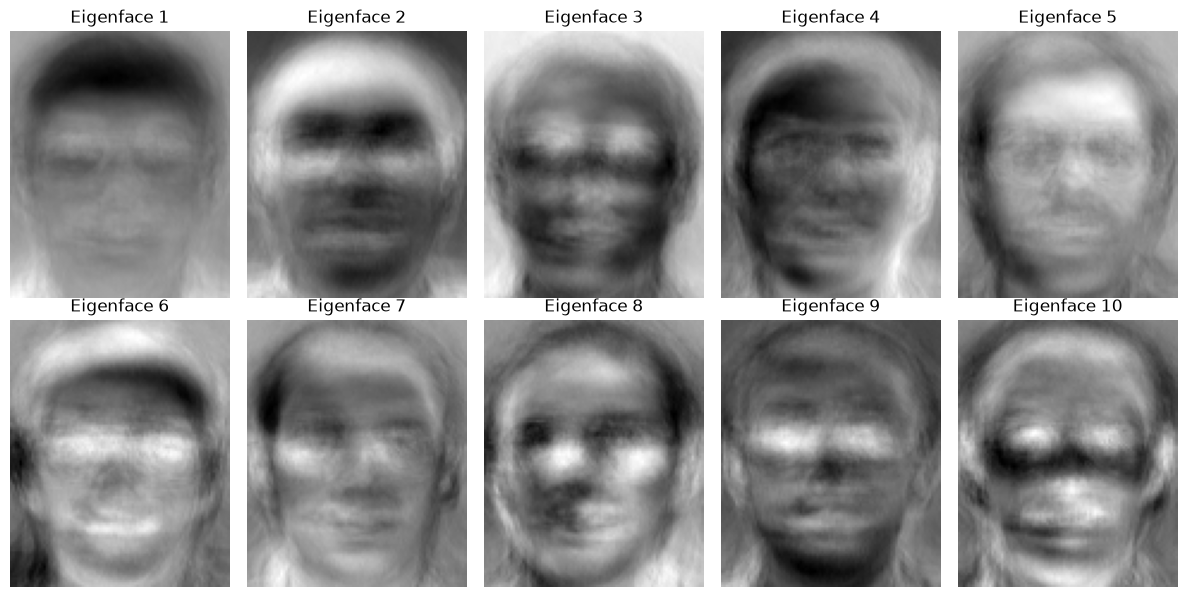

In [39]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        eigenfaces_svd[:, i].reshape(images.shape[1:]),
        cmap="gray"
    )
    plt.title(f"Eigenface {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.savefig("eigenfaces.png", dpi=150)
plt.show()

In [40]:
components = eigenfaces_svd[:, :n_components_90]

X_train_pca = X_train_centered @ components
X_test_pca = X_test_centered @ components

print("Original training shape:", X_train.shape)
print("Reduced training shape:", X_train_pca.shape)
print("Original test shape:", X_test.shape)
print("Reduced test shape:", X_test_pca.shape)

Original training shape: (320, 10304)
Reduced training shape: (320, 99)
Original test shape: (80, 10304)
Reduced test shape: (80, 99)


comparing the reconstructed quality and storage with the original pixel representation.

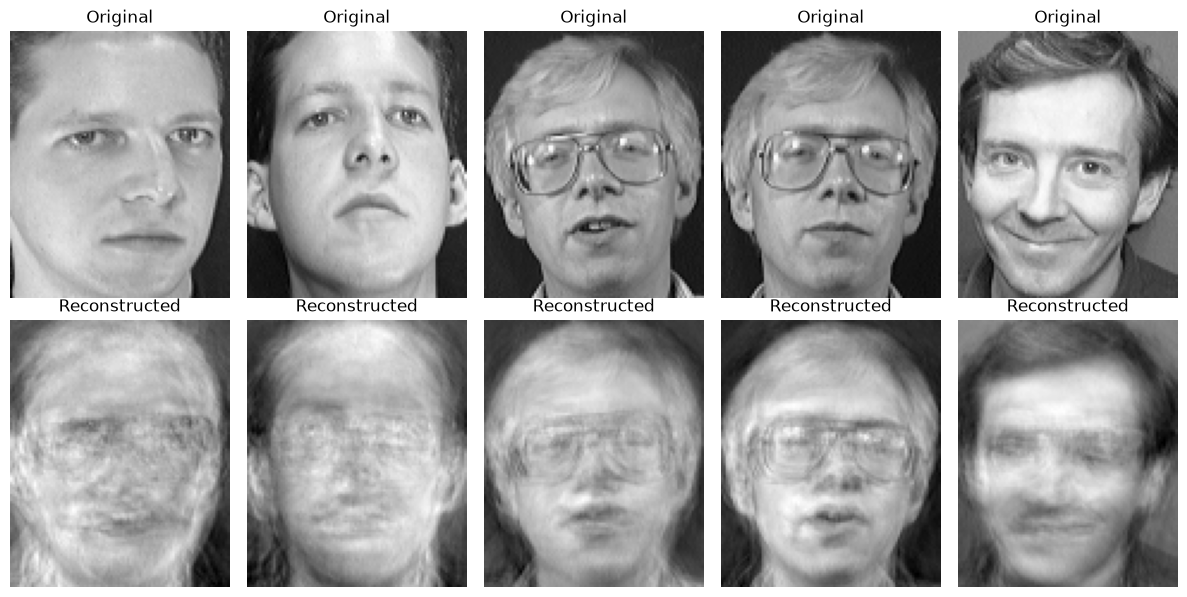

In [41]:
X_test_reconstructed = (
    X_test_pca @ components.T
) + mean_face

plt.figure(figsize=(12, 6))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        X_test[i].reshape(images.shape[1:]),
        cmap="gray"
    )
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(
        X_test_reconstructed[i].reshape(images.shape[1:]),
        cmap="gray"
    )
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.savefig("reconstruction.png", dpi=150)
plt.show()

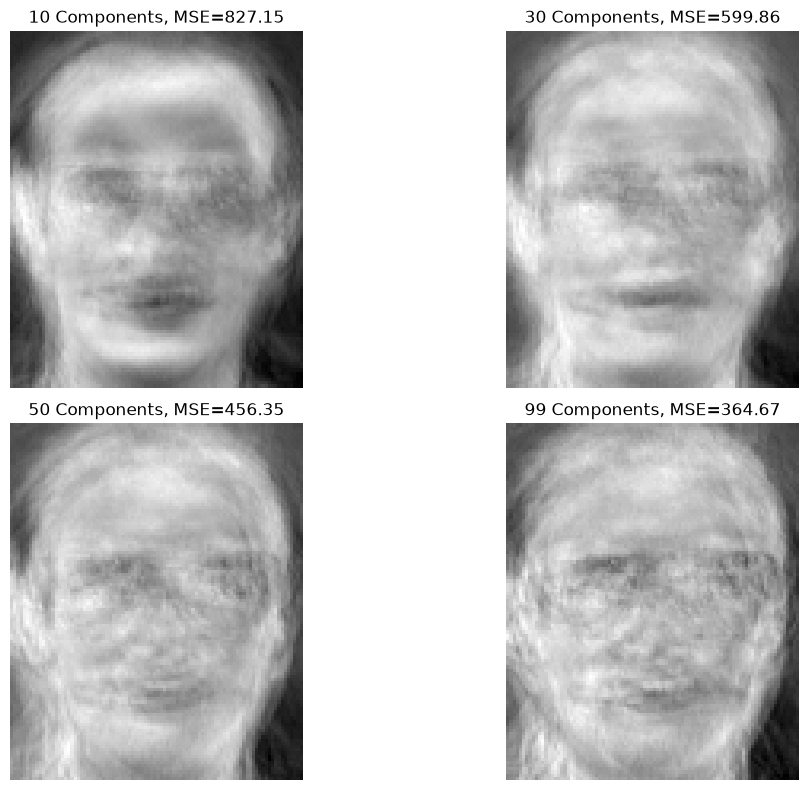

In [42]:
# Compare reconstruction using different numbers of components

component_counts = [10, 30, 50, 99]

plt.figure(figsize=(12, 8))

for i, k in enumerate(component_counts):

    # Reconstruct the first test image using k components
    reconstructed = (
        X_test_pca[0, :k] @ Vt[:k, :]
    ) + mean_face

    mse = np.mean((X_test[0] - reconstructed) ** 2)

    plt.subplot(2, 2, i + 1)
    plt.imshow(reconstructed.reshape(112, 92), cmap="gray")
    plt.title(f"{k} Components, MSE={mse:.2f}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [43]:
reconstruction_mse = np.mean(
    (X_test - X_test_reconstructed) ** 2
)

original_storage_values = X_train.shape[0] * X_train.shape[1]

compressed_storage_values = (
    X_train_pca.size
    + components.size
    + mean_face.size
)

compression_ratio = (
    original_storage_values / compressed_storage_values
)

storage_reduction = (
    1 - compressed_storage_values / original_storage_values
) * 100

print("Reconstruction MSE:", reconstruction_mse)
print("Original training pixel values:", original_storage_values)
print("PCA coefficients:", X_train_pca.size)
print("PCA basis values:", components.size)
print("Mean face values:", mean_face.size)
print("Total PCA storage values:", compressed_storage_values)
print("Original/PCA storage ratio:", compression_ratio)
print("Storage reduction (%):", storage_reduction)

Reconstruction MSE: 323.2065793209405
Original training pixel values: 3297280
PCA coefficients: 31680
PCA basis values: 1020096
Mean face values: 10304
Total PCA storage values: 1062080
Original/PCA storage ratio: 3.104549563121422
Storage reduction (%): 67.78920807453417


In [44]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Train labels:", np.unique(y_train))
print("Test labels:", np.unique(y_test))
print("Train pixel range:", X_train.min(), X_train.max())
print("Test pixel range:", X_test.min(), X_test.max())

X_train: (320, 10304)
X_test: (80, 10304)
y_train: (320,)
y_test: (80,)
Train labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]
Test labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]
Train pixel range: 0 251
Test pixel range: 0 244


Part C - Recognition in PCA Space

identifying the closest stored training face

In [45]:
def nearest_face(train_data, train_labels, test_data):
    predictions = []
    matched_indices = []

    for test_image in test_data:
        distances = np.linalg.norm(
            train_data - test_image,
            axis=1
        )

        nearest_index = np.argmin(distances)

        predictions.append(train_labels[nearest_index])
        matched_indices.append(nearest_index)

    return np.array(predictions), np.array(matched_indices)

In [46]:
raw_predictions, raw_matches = nearest_face(
    X_train, y_train, X_test
)

pca_predictions, pca_matches = nearest_face(
    X_train_pca, y_train, X_test_pca
)

raw_accuracy = np.mean(raw_predictions == y_test)
pca_accuracy = np.mean(pca_predictions == y_test)

print("Raw-pixel accuracy:", raw_accuracy)
print("PCA accuracy:", pca_accuracy)

Raw-pixel accuracy: 0.0125
PCA accuracy: 0.9875


Correct matches: 79
Incorrect matches: 1


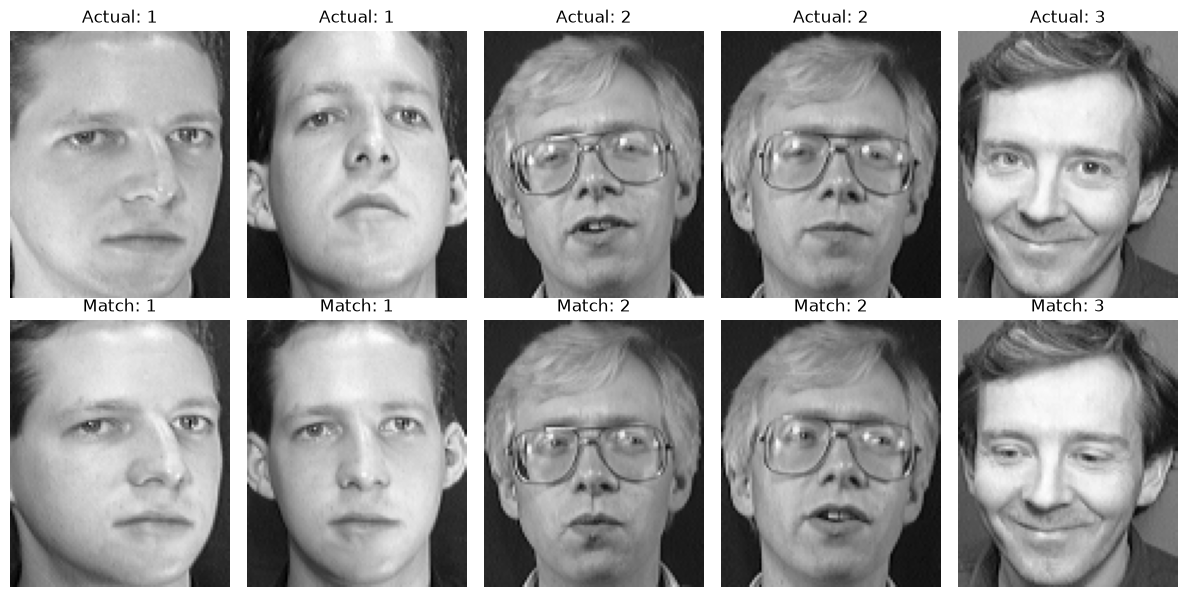

In [47]:
correct_indices = np.where(pca_predictions == y_test)[0]
incorrect_indices = np.where(pca_predictions != y_test)[0]

print("Correct matches:", len(correct_indices))
print("Incorrect matches:", len(incorrect_indices))

if len(correct_indices) > 0:
    plt.figure(figsize=(12, 6))

    for position, test_index in enumerate(correct_indices[:5]):
        train_index = pca_matches[test_index]

        plt.subplot(2, 5, position + 1)
        plt.imshow(
            X_test[test_index].reshape(images.shape[1:]),
            cmap="gray"
        )
        plt.title(f"Actual: {y_test[test_index]}")
        plt.axis("off")

        plt.subplot(2, 5, position + 6)
        plt.imshow(
            X_train[train_index].reshape(images.shape[1:]),
            cmap="gray"
        )
        plt.title(f"Match: {y_train[train_index]}")
        plt.axis("off")

    plt.tight_layout()
    plt.savefig("correct_matches.png", dpi=150)
    plt.show()

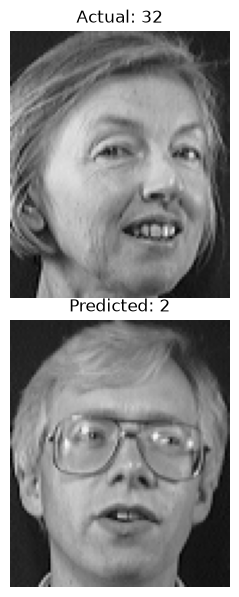

In [48]:
if len(incorrect_indices) > 0:
    plt.figure(figsize=(12, 6))

    for position, test_index in enumerate(incorrect_indices[:5]):
        train_index = pca_matches[test_index]

        plt.subplot(2, 5, position + 1)
        plt.imshow(
            X_test[test_index].reshape(images.shape[1:]),
            cmap="gray"
        )
        plt.title(f"Actual: {y_test[test_index]}")
        plt.axis("off")

        plt.subplot(2, 5, position + 6)
        plt.imshow(
            X_train[train_index].reshape(images.shape[1:]),
            cmap="gray"
        )
        plt.title(f"Predicted: {y_train[train_index]}")
        plt.axis("off")

    plt.tight_layout()
    plt.savefig("incorrect_matches.png", dpi=150)
    plt.show()
else:
    print("No incorrect PCA matches in this test set.")

Part D - Traditional Machine Learning

In [49]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# KNN classifier
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

knn_model.fit(X_train_pca, y_train)
knn_predictions = knn_model.predict(X_test_pca)

knn_accuracy = np.mean(knn_predictions == y_test)


# SVM classifier
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10)
)

svm_model.fit(X_train_pca, y_train)
svm_predictions = svm_model.predict(X_test_pca)

svm_accuracy = np.mean(svm_predictions == y_test)

print("KNN accuracy:", knn_accuracy)
print("SVM accuracy:", svm_accuracy)

KNN accuracy: 0.825
SVM accuracy: 0.9375


In [50]:
component_counts = sorted(set(
    k for k in [10, 20, 30, 50, 75, n_components_90]
    if k <= eigenfaces_svd.shape[1]
))

experiment_results = []

for k in component_counts:
    reduced_components = eigenfaces_svd[:, :k]

    train_features = X_train_centered @ reduced_components
    test_features = X_test_centered @ reduced_components

    similarity_predictions, _ = nearest_face(
        train_features, y_train, test_features
    )

    similarity_accuracy = np.mean(
        similarity_predictions == y_test
    )

    for neighbors in [1, 3, 5]:
        knn = make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=neighbors)
        )

        knn.fit(train_features, y_train)
        predictions = knn.predict(test_features)

        experiment_results.append({
            "Components": k,
            "Method": f"KNN (k={neighbors})",
            "Accuracy": np.mean(predictions == y_test)
        })

    # Experiment with SVM C values
    for c_value in [1, 10, 100]:
        svm = make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", C=c_value)
        )

        svm.fit(train_features, y_train)
        predictions = svm.predict(test_features)

        experiment_results.append({
            "Components": k,
            "Method": f"SVM (C={c_value})",
            "Accuracy": np.mean(predictions == y_test)
        })

    experiment_results.append({
        "Components": k,
        "Method": "Nearest Face",
        "Accuracy": similarity_accuracy
    })

for result in experiment_results:
    print(
        f"Components: {result['Components']:>3} | "
        f"{result['Method']:<18} | "
        f"Accuracy: {result['Accuracy']:.2%}"
    )

Components:  10 | KNN (k=1)          | Accuracy: 93.75%
Components:  10 | KNN (k=3)          | Accuracy: 85.00%
Components:  10 | KNN (k=5)          | Accuracy: 80.00%
Components:  10 | SVM (C=1)          | Accuracy: 92.50%
Components:  10 | SVM (C=10)         | Accuracy: 95.00%
Components:  10 | SVM (C=100)        | Accuracy: 95.00%
Components:  10 | Nearest Face       | Accuracy: 97.50%
Components:  20 | KNN (k=1)          | Accuracy: 97.50%
Components:  20 | KNN (k=3)          | Accuracy: 90.00%
Components:  20 | KNN (k=5)          | Accuracy: 87.50%
Components:  20 | SVM (C=1)          | Accuracy: 95.00%
Components:  20 | SVM (C=10)         | Accuracy: 95.00%
Components:  20 | SVM (C=100)        | Accuracy: 95.00%
Components:  20 | Nearest Face       | Accuracy: 96.25%
Components:  30 | KNN (k=1)          | Accuracy: 97.50%
Components:  30 | KNN (k=3)          | Accuracy: 95.00%
Components:  30 | KNN (k=5)          | Accuracy: 90.00%
Components:  30 | SVM (C=1)          | Accuracy:

In [51]:
results = [
    ("Raw Pixel Nearest Neighbor", X_train.shape[1], raw_accuracy),
    ("PCA Nearest Neighbor", n_components_90, pca_accuracy),
    ("PCA + KNN", n_components_90, knn_accuracy),
    ("PCA + SVM", n_components_90, svm_accuracy)
]

print(f"{'Method':<30} {'Features':>10} {'Accuracy':>12}")
print("-" * 55)

for method, features, accuracy in results:
    print(
        f"{method:<30} "
        f"{features:>10} "
        f"{accuracy:>11.2%}"
    )

Method                           Features     Accuracy
-------------------------------------------------------
Raw Pixel Nearest Neighbor          10304       1.25%
PCA Nearest Neighbor                   99      98.75%
PCA + KNN                              99      82.50%
PCA + SVM                              99      93.75%


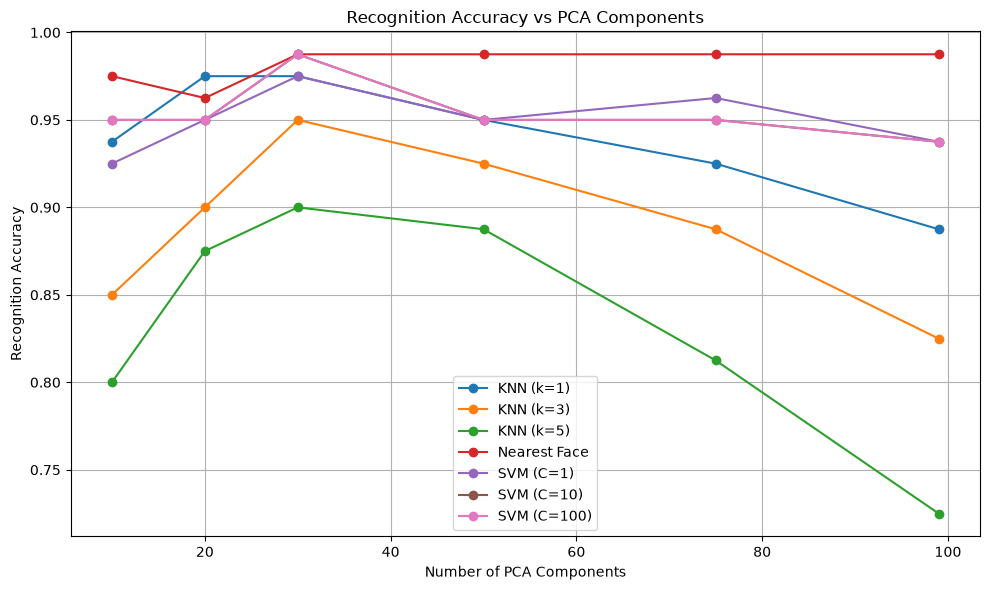

In [52]:
methods = sorted(set(
    result["Method"] for result in experiment_results
))

plt.figure(figsize=(10, 6))

for method in methods:
    selected_results = [
        result for result in experiment_results
        if result["Method"] == method
    ]

    plt.plot(
        [result["Components"] for result in selected_results],
        [result["Accuracy"] for result in selected_results],
        marker="o",
        label=method
    )

plt.xlabel("Number of PCA Components")
plt.ylabel("Recognition Accuracy")
plt.title("Recognition Accuracy vs PCA Components")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("component_experiment.png", dpi=150)
plt.show()